# TP2 — Dynamical Mean-Field Theory: from the Mott transition to trapped fermions in 1D

Master 2 ICFP — computer lab accompanying the DMFT lecture notes.

In this lab we write, step by step, a DMFT code based on a single impurity solver, the **iterated perturbation theory (IPT)**, and we use it all the way: first for the Mott transition of the homogeneous Hubbard model, then, in its real-space version, for fermions in a one-dimensional trap.

| § | Topic | Lecture notes |
|---|---|---|
| 0 | Toolbox: Matsubara grids and Fourier transforms | Ch. 2 |
| 1 | DMFT for the Hubbard model on the Bethe lattice with the IPT solver | Ch. 4, 6 |
| 2 | The Mott transition with IPT: $Z$, double occupancy, phase diagram | Ch. 6 |
| 3 | Real-space DMFT with IPT for inhomogeneous one-dimensional chains | Ch. 7 |
| 4 | Trapped fermions in 1D: density profiles, DMFT versus mean field and exact results | Ch. 7 |

**Conventions.** $\hbar = k_B = 1$. In §1–2 the energy unit is the half-bandwidth $D$ of the semicircular density of states; in §3–4 it is the hopping $t$ of the chain. We always work at fixed temperature $T = 1/\beta$ on the Matsubara axis, and we only consider paramagnetic solutions.

**Typical running times** on a laptop are indicated before the long cells. Cells starting with `# TODO` are for you to complete (replace the `...`); all the other cells are given.

In [1]:
import time
import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

# 0. Toolbox: Matsubara frequencies and Fourier transforms

For fermions, a Green's function is defined on $\tau\in[0,\beta]$ and expanded on the Matsubara frequencies $\omega_n = (2n+1)\pi/\beta$:

$$
G(i\omega_n)=\int_0^\beta d\tau\, e^{i\omega_n\tau}G(\tau),\qquad
G(\tau)=\frac1\beta\sum_{n=-\infty}^{+\infty}e^{-i\omega_n\tau}G(i\omega_n).
$$

Two practical remarks (Sec. 2.3 of the notes):

1. Since $G(-i\omega_n)=G(i\omega_n)^*$, we only store the $n_\omega$ **positive** frequencies, and
$G(\tau)=\frac{2}{\beta}\sum_{n\ge 0}\mathrm{Re}\left[e^{-i\omega_n\tau}G(i\omega_n)\right]$.
2. $G(i\omega_n)\simeq 1/(i\omega_n)$ at large frequency: the sum converges very slowly, and $G(\tau)$ jumps at $\tau=0$. We therefore subtract the tail and add its exact transform, $-1/2$ (eq. 2.23 of the notes):
$$
G(\tau)=\frac{2}{\beta}\sum_{n\ge 0}\mathrm{Re}\left\{e^{-i\omega_n\tau}\left[G(i\omega_n)-\frac{1}{i\omega_n}\right]\right\}-\frac12,\qquad 0<\tau<\beta .
$$

The inverse transform $\tau\to i\omega_n$ is a simple integral, done with the trapezoidal rule on a fine $\tau$ grid. The two transforms are matrix–vector products; we build the matrices once and reuse them at every DMFT iteration.

In [2]:
class MatsubaraGrid:
    '''Fermionic Matsubara frequencies and imaginary-time grid at inverse temperature beta.

    Only the n_w positive frequencies w_n = (2n+1) pi / beta are stored, because
    G(-i w_n) = G(i w_n)^*.  The tau grid has n_tau equally spaced points on [0, beta].
    '''

    def __init__(self, beta, n_w, n_tau=None):
        self.beta = beta
        self.wn = (2 * np.arange(n_w) + 1) * np.pi / beta     # w_0, w_1, ...
        self.iw = 1j * self.wn                                # i w_n, convenient in formulas
        if n_tau is None:
            n_tau = 4 * n_w + 1                               # a few tau points per frequency
        self.tau = np.linspace(0.0, beta, n_tau)

        # Fourier matrices, built once: (n_tau x n_w) and (n_w x n_tau)
        self.exp_minus = np.exp(-1j * np.outer(self.tau, self.wn))         # e^{-i w_n tau}
        dtau = self.tau[1] - self.tau[0]
        trapezoid = np.full(n_tau, dtau)
        trapezoid[0] = trapezoid[-1] = dtau / 2                             # trapezoidal weights
        self.exp_plus = np.exp(1j * np.outer(self.wn, self.tau)) * trapezoid  # e^{+i w_n tau} dtau

    def to_tau(self, G_iw):
        '''G(i w_n) -> G(tau) on [0, beta], with the 1/(i w_n) tail treated analytically.'''
        G_without_tail = G_iw - 1.0 / self.iw   # substracting the tail helps for the convergence: make the edges of the FT cleaner
        return 2.0 / self.beta * (self.exp_minus @ G_without_tail).real - 0.5

    def to_iw(self, G_tau):
        '''G(tau) -> G(i w_n) = int_0^beta dtau e^{i w_n tau} G(tau).'''
        return self.exp_plus @ G_tau

**Test on the free fermion** (Sec. 2.4 of the notes). For a single level of energy $\varepsilon$,
$G(i\omega_n)=1/(i\omega_n-\varepsilon)$ and $G(\tau)=-e^{-\varepsilon\tau}/(1+e^{-\beta\varepsilon})$ for $0<\tau<\beta$. We check both transforms against these exact results.

eps = -1.0:  max |G(tau) - exact| = 9.9e-04,   max |FT(FT^-1(G)) - G| = 6.7e-04
eps = +0.0:  max |G(tau) - exact| = 0.0e+00,   max |FT(FT^-1(G)) - G| = 6.7e-04
eps = +1.0:  max |G(tau) - exact| = 9.9e-04,   max |FT(FT^-1(G)) - G| = 6.7e-04


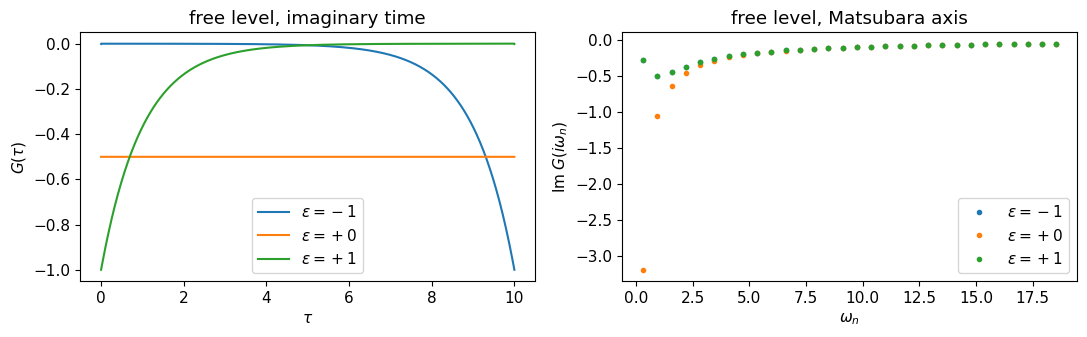

In [3]:
beta = 10.0
grid = MatsubaraGrid(beta, n_w=512)  # if the grid is coarser, the edges of the results oscillate, it becomes poorer

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for eps in [-1.0, 0.0, 1.0]:
    G_iw = 1.0 / (grid.iw - eps)
    G_tau_exact = -np.exp(-eps * grid.tau) / (1 + np.exp(-beta * eps))
    G_tau = grid.to_tau(G_iw)
    back = grid.to_iw(G_tau)
    print(f"eps = {eps:+.1f}:  max |G(tau) - exact| = {np.abs(G_tau - G_tau_exact).max():.1e},"
          f"   max |FT(FT^-1(G)) - G| = {np.abs(back - G_iw).max():.1e}")
    ax[0].plot(grid.tau, G_tau, label=rf"$\varepsilon={eps:+.0f}$")
    ax[1].plot(grid.wn[:30], G_iw.imag[:30], "o", ms=3, label=rf"$\varepsilon={eps:+.0f}$")
ax[0].set(xlabel=r"$\tau$", ylabel=r"$G(\tau)$", title="free level, imaginary time")
ax[1].set(xlabel=r"$\omega_n$", ylabel=r"Im $G(i\omega_n)$", title="free level, Matsubara axis")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

The transform to $\tau$ is exact up to the truncation of the frequency sum. The round trip $i\omega_n\to\tau\to i\omega_n$ has a small error coming from the trapezoidal rule, which decreases as the $\tau$ grid is refined. This accuracy is sufficient for what follows.

# 1. DMFT for the Hubbard model on the Bethe lattice, with the IPT solver

## 1.1 Reminder (Ch. 4 and 6 of the notes)

We solve the half-filled Hubbard model
$$
H=-t\sum_{\langle ij\rangle\sigma}c^\dagger_{i\sigma}c_{j\sigma}+U\sum_i n_{i\uparrow}n_{i\downarrow}-\mu\sum_{i\sigma}n_{i\sigma}
$$
on the Bethe lattice with infinite coordination, whose non-interacting density of states is the semicircle of half-width $D=2t$:
$$
D(\varepsilon)=\frac{2}{\pi D^2}\sqrt{D^2-\varepsilon^2}.
$$

The DMFT equations are particularly simple on this lattice (eq. 6.2 of the notes): the hybridisation function is proportional to the local Green's function,
$$
\Delta(i\omega_n)=t^2\,G(i\omega_n),\qquad
\mathcal G_0^{-1}(i\omega_n)=i\omega_n+\mu-t^2 G(i\omega_n).
$$

**IPT solver.** At half filling, $\mu=U/2$ exactly cancels the Hartree term $U\langle n_{-\sigma}\rangle=U/2$, and the IPT self-energy is the second-order diagram computed with the Weiss field (eq. 6.6):
$$
\Sigma(\tau)=U^2\,\mathcal G_0(\tau)^3 ,
$$
where $\Sigma$ denotes the self-energy without its Hartree part, and $\mathcal G_0^{-1}=i\omega_n-t^2G$.

**The loop** (Sec. 4.6 of the notes):
1. Weiss field: $\mathcal G_0^{-1}(i\omega_n)=i\omega_n-t^2G(i\omega_n)$;
2. impurity solver: $\mathcal G_0(i\omega_n)\to\mathcal G_0(\tau)\to\Sigma(\tau)=U^2\mathcal G_0(\tau)^3\to\Sigma(i\omega_n)$;
3. new local Green's function from the impurity Dyson equation: $G=\left[\mathcal G_0^{-1}-\Sigma\right]^{-1}$;
4. mix with the previous $G$ and go back to 1, until $G$ stops changing.

**Particle–hole symmetry.** At half filling the spectral function is symmetric, $A(\omega)=A(-\omega)$, so $G(i\omega_n)$ and $\Sigma(i\omega_n)$ are purely imaginary (Sec. 2.3 of the notes). Small numerical errors break this symmetry, and the iteration then drifts towards a spurious, non-symmetric solution near the transition. We therefore set the real parts to zero at each iteration: try removing this line to see what happens.

In [4]:
D = 1.0           # half-bandwidth of the semicircle: our energy unit in sections 1-4
t_hop = D / 2     # Bethe-lattice hopping, D = 2t


def G_semicircle(z):
    '''Hilbert transform of the semicircle, G(z) = int de D(e)/(z-e), for Im z > 0.

    Writing sqrt(z^2 - D^2) as sqrt(z-D) * sqrt(z+D) selects the correct branch
    (Im G < 0) both on the Matsubara axis and just above the real axis.
    '''
    return 2.0 / (z + np.sqrt(z - D) * np.sqrt(z + D))


def ipt_self_energy(G0_iw, U, grid):
    '''IPT self-energy at half filling (Hartree term excluded): Sigma(tau) = U^2 G0(tau)^3.'''
    G0_tau = grid.to_tau(G0_iw)
    return grid.to_iw(U**2 * G0_tau**3)

## 1.2 The DMFT–IPT loop

**Task.** Write the function `dmft_ipt(U, grid, G_start=None, mixing=0.5, tol=1e-8, max_iter=3000)` implementing the loop above. It should return the converged $G(i\omega_n)$ and $\Sigma(i\omega_n)$. The optional `G_start` allows us to start from a given solution: from the free semicircle (default) or from a previously converged solution, which is essential to follow the metallic and insulating solutions across the transition.

In [5]:
# TODO: complete the DMFT-IPT loop
def dmft_ipt(U, grid, G_start=None, mixing=0.5, tol=1e-8, max_iter=3000, verbose=False):
    '''Paramagnetic DMFT for the half-filled Hubbard model on the Bethe lattice, IPT solver.'''
    G = G_semicircle(grid.iw) if G_start is None else G_start.copy()

    for iteration in range(1, max_iter + 1):
        # 1) Weiss field from the Bethe-lattice self-consistency (mu = U/2 cancels the Hartree term)
        G0_iw = 1/(grid.iw - t_hop**2*G)

        # 2) impurity solver: IPT self-energy (use ipt_self_energy), then impose particle-hole symmetry
        Sigma_iw = ipt_self_energy(G0_iw, U, grid)
        Sigma_iw = 1j*Sigma_iw.imag
        
        # 3) impurity Dyson equation: new local Green's function (impose particle-hole symmetry)
        G_new = 1/(1/G0_iw - Sigma_iw)
        G_new.real = 0 #particle-hole symmetry
        
        # 4) convergence check (max |G_new - G|) and linear mixing
        error = max(np.abs(G_new-G))
        G = G*(1-mixing) + G_new*mixing
        if error < tol:
            break

    return {"G": G, "Sigma": Sigma_iw, "G0": G0_iw, "U": U, "grid": grid,
            "iterations": iteration, "error": error}

## 1.3 Observables

From the converged solution we compute, directly on the Matsubara axis:

* the **quasiparticle weight** (eq. 2.65 of the notes), $Z\simeq\left[1-\mathrm{Im}\,\Sigma(i\omega_0)/\omega_0\right]^{-1}$;
* the **double occupancy** (Sec. 6.5), $U\langle n_\uparrow n_\downarrow\rangle=\frac{U}{4}+\frac{2}{\beta}\sum_{n\ge0}\mathrm{Re}\left[\Sigma(i\omega_n)G(i\omega_n)\right]$, valid at half filling, with $\Sigma$ the self-energy without its Hartree part;
* the **spectral weight at the Fermi level** without analytic continuation (Sec. 6.4.3), $-\beta G(\beta/2)/\pi\to A(\omega=0)$ at low $T$.

For the last one, note that $e^{-i\omega_n\beta/2}=-i(-1)^n$, so $G(\beta/2)=\frac{2}{\beta}\sum_{n\ge0}(-1)^n\,\mathrm{Im}\,G(i\omega_n)$, and we again treat the $1/i\omega_n$ tail exactly.

In [6]:
def quasiparticle_weight(res):
    '''Z = 1 / (1 - Im Sigma(i w_0) / w_0): the Matsubara estimate of eq. (2.65).'''
    w0 = res["grid"].wn[0]
    return 1.0 / (1.0 - res["Sigma"][0].imag / w0)


def double_occupancy(res):
    '''<n_up n_dn> = 1/4 + (2 / (beta U)) sum_{n>=0} Re[Sigma G]   (half filling).'''
    if res["U"] == 0:
        return 0.25
    beta = res["grid"].beta
    return 0.25 + 2.0 / (beta * res["U"]) * np.sum((res["Sigma"] * res["G"]).real)


def spectral_weight_fermi_level(res):
    '''-beta G(beta/2) / pi, which tends to A(omega = 0) at low temperature.'''
    grid = res["grid"]
    sign = (-1.0) ** np.arange(len(grid.wn))
    G_half_beta = 2.0 / grid.beta * np.sum(sign * (res["G"].imag + 1.0 / grid.wn)) - 0.5
    return -grid.beta * G_half_beta / np.pi

## 1.4 First checks

* At $U=0$ the loop must converge immediately to the semicircle, with $Z=1$, $\langle n_\uparrow n_\downarrow\rangle=1/4$ and $A(0)=D(0)=2/(\pi D)$.
* At $U=2D$ we expect a correlated metal with $Z\approx0.35$ (Fig. 6.4 of the notes).
* At $U=4D$, starting from the atomic limit $G=\frac{1/2}{i\omega_n-U/2}+\frac{1/2}{i\omega_n+U/2}$, we expect a Mott insulator.

In [7]:
beta = 100.0
grid = MatsubaraGrid(beta, n_w=1024)          # w_max = 2 pi n_w / beta ~ 64 D


def atomic_G(U, grid):
    '''Green's function of the Hubbard atom at half filling: a good starting point for the insulator.'''
    return 0.5 / (grid.iw - U / 2) + 0.5 / (grid.iw + U / 2)


for U, start, label in [(0.0, None, "free start"), (2.0, None, "free start"),
                        (4.0, atomic_G(4.0, grid), "atomic start")]:
    t0 = time.time()
    res = dmft_ipt(U, grid, G_start=start)
    print(f"U = {U:.1f} D ({label:12s}): {res['iterations']:4d} iterations ({time.time()-t0:.1f} s)"
          f"   Z = {quasiparticle_weight(res):.3f}   <n_up n_dn> = {double_occupancy(res):.4f}"
          f"   -beta G(beta/2)/pi = {spectral_weight_fermi_level(res):.3f}")
print(f"\nnon-interacting value of A(0) = 2/(pi D) = {2/np.pi:.3f}")

U = 0.0 D (free start  ):    1 iterations (0.0 s)   Z = 1.000   <n_up n_dn> = 0.2500   -beta G(beta/2)/pi = 0.636
U = 2.0 D (free start  ):   32 iterations (0.4 s)   Z = 0.346   <n_up n_dn> = 0.0941   -beta G(beta/2)/pi = 0.632
U = 4.0 D (atomic start):   29 iterations (0.3 s)   Z = 0.000   <n_up n_dn> = 0.0143   -beta G(beta/2)/pi = 0.000

non-interacting value of A(0) = 2/(pi D) = 0.637


# 2. The Mott transition with IPT

## 2.1 Matsubara-axis signatures of the metal and of the insulator

**Task.** For $\beta D=100$, plot $\mathrm{Im}\,G(i\omega_n)$ and $\mathrm{Im}\,\Sigma(i\omega_n)$ for $U/D=2$ (metal) and $U/D=4$ (insulator), and interpret the low-frequency behaviour (Sec. 6.4.3 of the notes).

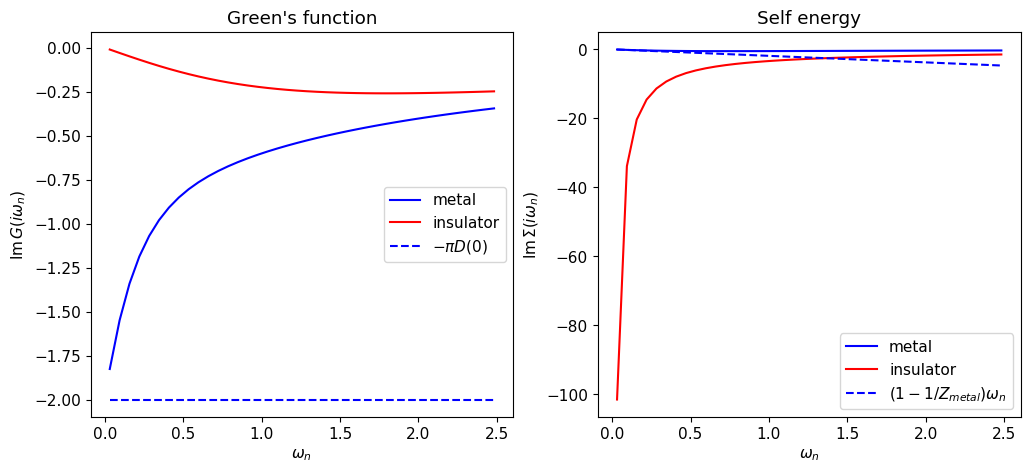

In [8]:
# TODO: converge a metal (U = 2D, free start) and an insulator (U = 4D, atomic start)
D = 1
beta = 100
t_hop = D/2
grid = MatsubaraGrid(beta, n_w=1024)  
N = 40

metal = dmft_ipt(2*D, grid, G_start=None, mixing=0.5, tol=1e-8, max_iter=3000, verbose=False)
insulator = dmft_ipt(4*D, grid, G_start=atomic_G(4*D,grid), mixing=0.5, tol=1e-8, max_iter=3000, verbose=False)
Z_metal = quasiparticle_weight(metal)
Z_insulator = quasiparticle_weight(insulator)

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(1,2,1)
ax2 = fig.add_subplot(1,2,2)

ax1.plot(grid.iw.imag[:N],metal["G"].imag[:N],"b-",label="metal")
ax1.plot(grid.iw.imag[:N],insulator["G"].imag[:N],"r-",label="insulator")
ax1.plot(grid.iw.imag[:N],[-2/D for i in range(N)],"b--",label=r"$-\pi D(0)$")
ax1.set_title("Green's function")
ax1.set_xlabel(r"$\omega_n$")
ax1.set_ylabel(r"$\mathrm{Im}\,G(i\omega_n)$")
ax1.legend()


ax2.plot(grid.iw.imag[:N],metal["Sigma"].imag[:N],"b-",label="metal")
ax2.plot(grid.iw.imag[:N],insulator["Sigma"].imag[:N],"r-",label="insulator")
ax2.plot(grid.iw.imag[:N],(1-1/Z_metal)*grid.iw.imag[:N],"b--",label=r"$(1-1/Z_{metal})\omega_n$")
#ax2.plot(grid.iw.imag[:N],(1-1/Z_insulator)*grid.iw.imag[:N],"r--",label=r"$(1-1/Z_{insulator})\omega_n$")
ax2.set_title("Self energy")
ax2.set_xlabel(r"$\omega_n$")
ax2.set_ylabel(r"$\mathrm{Im}\,\Sigma(i\omega_n)$")
ax2.legend()
plt.show()
# TODO: plot Im G(i w_n) and Im Sigma(i w_n) for both, for the first ~40 frequencies.
# Hints: compare Im G at small w_n with -pi D(0) = -2/D; compare Im Sigma with (1 - 1/Z) w_n.

In the **metal**, $\mathrm{Im}\,G(i\omega_n)\to-\pi A(0)=-2/D$ as $\omega_n\to0$ (pinning of the quasiparticle peak, Sec. 6.4.1), and $\mathrm{Im}\,\Sigma(i\omega_n)$ is linear at low frequency with slope $1-1/Z$: a Fermi liquid.
In the **insulator**, $\mathrm{Im}\,G(i\omega_n)\to0$ (no spectral weight at the Fermi level) and $\mathrm{Im}\,\Sigma(i\omega_n)\sim-\alpha/\omega_n$ diverges, as in the atomic limit (eq. 2.65 of the notes).

## 2.2 Hysteresis: coexistence of metal and insulator

**Task.** Run the function `ipt_sweep(U_values, beta)` that performs two sweeps at fixed temperature: one with increasing $U$ starting from the metal, and one with decreasing $U$ starting from the insulator (atomic-limit start at the largest $U$). Store $Z$, $\langle n_\uparrow n_\downarrow\rangle$ and $-\beta G(\beta/2)/\pi$ along both sweeps. Plot them for $\beta D=100$ and identify the coexistence region $U_{c1}<U<U_{c2}$ (Sec. 6.5 of the notes).

In [9]:
# Helper functions (given)
def n_frequencies(beta, w_max=40.0):
    '''Number of Matsubara frequencies needed to reach w_max (at least 256).'''
    return max(256, int(w_max * beta / (2 * np.pi)))


def plot_sweep(sweep, title=""):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    for key, ylabel, k in [("docc", r"$\langle n_\uparrow n_\downarrow\rangle$", 0),
                           ("Z", r"$Z$", 1), ("A0", r"$-\beta G(\beta/2)/\pi$", 2)]:
        ax[k].plot(sweep["U"], sweep["up"][key], "o-", ms=4, label="U increasing (from metal)")
        ax[k].plot(sweep["U"], sweep["down"][key], "s-", ms=3, label="U decreasing (from insulator)")
        ax[k].set(xlabel=r"$U/D$", ylabel=ylabel)
    ax[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()

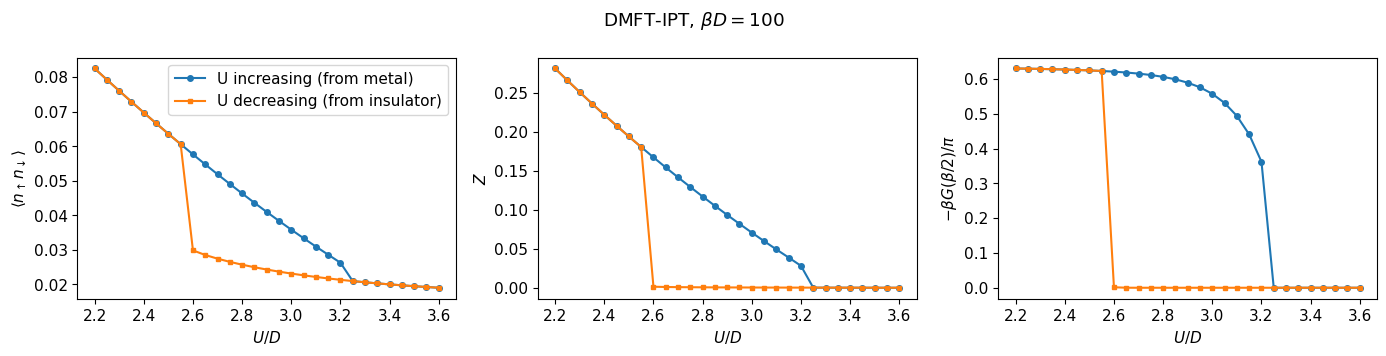

In [10]:
def ipt_sweep(U_values, beta, tol=1e-7):
    '''Increasing-U sweep from the metal and decreasing-U sweep from the insulator.'''
    grid = MatsubaraGrid(beta, n_frequencies(beta))
    out = {"U": np.asarray(U_values), "beta": beta}
    for direction in ["up", "down"]:
        Us = U_values if direction == "up" else U_values[::-1]
        G = None if direction == "up" else atomic_G(Us[0], grid)
        Z, docc, A0 = [], [], []
        for U in Us:
            res = dmft_ipt(U, grid, G_start=G, tol=tol)
            G = res["G"]
            Z.append(quasiparticle_weight(res))
            docc.append(double_occupancy(res))
            A0.append(spectral_weight_fermi_level(res))
        order = slice(None) if direction == "up" else slice(None, None, -1)   # back to increasing U
        out[direction] = {"Z": np.array(Z)[order], "docc": np.array(docc)[order],
                          "A0": np.array(A0)[order]}
    return out


U_values = np.round(np.arange(2.2, 3.61, 0.05), 3)
sweep_ipt_100 = ipt_sweep(U_values, beta=100.0)
plot_sweep(sweep_ipt_100, r"DMFT-IPT, $\beta D=100$")

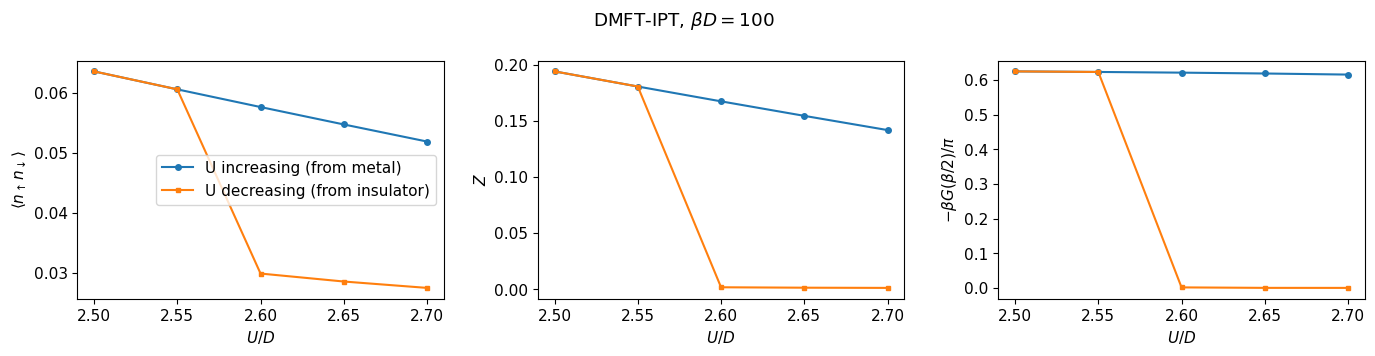

In [11]:
U_values = np.round(np.arange(2.50, 2.7, 0.05), 3)
sweep_ipt_100 = ipt_sweep(U_values, beta=100.0)
plot_sweep(sweep_ipt_100, r"DMFT-IPT, $\beta D=100$")

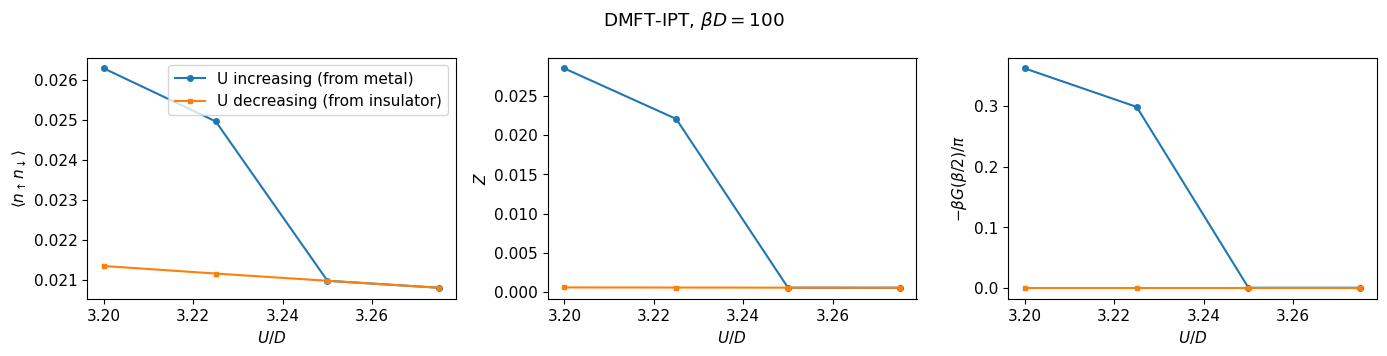

In [12]:
U_values = np.round(np.arange(3.2, 3.3, 0.025), 3)
sweep_ipt_100 = ipt_sweep(U_values, beta=100.0)
plot_sweep(sweep_ipt_100, r"DMFT-IPT, $\beta D=100$")

The graphs show that $U_{c1} \approx 2.58$ and $U_{c2} \approx 3.23$.

## 2.3 The phase diagram

**Task.** Repeat the sweeps for several temperatures. For each temperature, determine the coexistence region as the set of $U$ values where the two sweeps give different double occupancies, and plot its boundaries $U_{c1}(T)$ and $U_{c2}(T)$ in the $(U,T)$ plane. Where does the coexistence region end? Compare with Fig. 6.6 of the notes.

*Running time: less than a minute (the lowest temperature is the most expensive).*

In [13]:
# Helper function (given)
def plot_phase_diagram(phases, labels, markers, title="Paramagnetic phase diagram"):
    plt.figure(figsize=(6, 4.5))
    for phase, label, mk in zip(phases, labels, markers):
        T = np.array([1 / b for b, r in phase.items() if r is not None])
        Uc1 = np.array([r[0] for r in phase.values() if r is not None])
        Uc2 = np.array([r[1] for r in phase.values() if r is not None])
        plt.plot(Uc1, T, mk + "-", label=label + r": $U_{c1}(T)$")
        plt.plot(Uc2, T, mk + "--", mfc="white", label=label + r": $U_{c2}(T)$")
    plt.xlabel(r"$U/D$"); plt.ylabel(r"$T/D$"); plt.title(title)
    ax = plt.gca()
    ax.text(0.03, 0.05, "metal", transform=ax.transAxes)
    ax.text(0.97, 0.05, "Mott insulator", transform=ax.transAxes, ha="right")
    plt.legend(fontsize=9); plt.tight_layout(); plt.show()

T/D = 0.0500  coexistence region: None   (7 s)
T/D = 0.0400  coexistence region: (2.525, 2.55)   (12 s)
T/D = 0.0286  coexistence region: (2.575, 2.775)   (17 s)
T/D = 0.0200  coexistence region: (2.575, 2.975)   (24 s)
T/D = 0.0133  coexistence region: (2.6, 3.15)   (40 s)
T/D = 0.0100  coexistence region: (2.6, 3.225)   (40 s)
T/D = 0.0067  coexistence region: (2.6, 3.275)   (103 s)


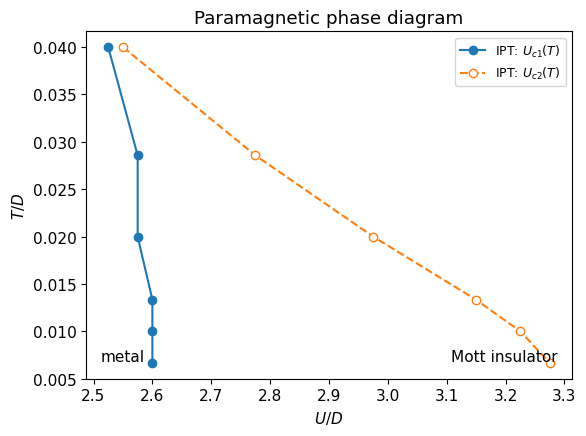

In [14]:
def coexistence_region(sweep, threshold=1e-3):
    '''(U_c1, U_c2): smallest and largest U where the two sweeps differ, or None if they never do.'''
    differ = np.abs(sweep["up"]["docc"] - sweep["down"]["docc"]) > threshold
    if not differ.any():
        return None
    return sweep["U"][differ].min(), sweep["U"][differ].max()

U_values = np.round(np.arange(2.2, 3.61, 0.025), 3)
sweep_ipt_100 = ipt_sweep(U_values, beta=100.0)
betas_ipt = [20.0, 25.0, 35.0, 50.0, 75.0, 100.0, 150.0]
phase_ipt = {}
t0 = time.time()
for beta in betas_ipt:
    sweep = sweep_ipt_100 if beta == 100.0 else ipt_sweep(U_values, beta)
    phase_ipt[beta] = coexistence_region(sweep)
    print(f"T/D = {1/beta:.4f}  coexistence region: {phase_ipt[beta]}   ({time.time() - t0:.0f} s)")


plot_phase_diagram([phase_ipt], ["IPT"], ["o"])

The coexistence region shrinks as $T$ increases and closes at a critical point $T_c\approx0.04D$, $U\approx2.55D$; above it there is a smooth crossover from a bad metal to a bad insulator. With IPT, $U_{c1}\approx2.6D$ and $U_{c2}\approx3.3D$ at low temperature, while numerically exact methods give $U_{c1}\approx2.4D$ and $U_{c2}\approx2.9D$ (Sec. 6.5 of the notes): IPT is qualitatively right but overestimates the critical interactions.

**Task.**
1. Plot the double occupancy as a function of $T$ at $U=2.7D$, starting from the metal at low $T$. Interpret the result in terms of the entropy of the paramagnetic insulator (Sec. 6.5.2).

In [15]:
betas_ipt = np.flip([20.0, 25.0, 30,35.0,40,45, 50.0,55,60,65,70, 75.0,80,85,90,95, 100.0,105,110,115,120,125,130,135,140,145, 150.0])
#start at low T = large beta
U = 2.7*D
docc = []
G = None
for beta in betas_ipt:
    grid = MatsubaraGrid(beta, n_w = 512)
    res = dmft_ipt(U, grid, G_start=G, tol=1e-7)
    G = res["G"]
    docc.append(double_occupancy(res))

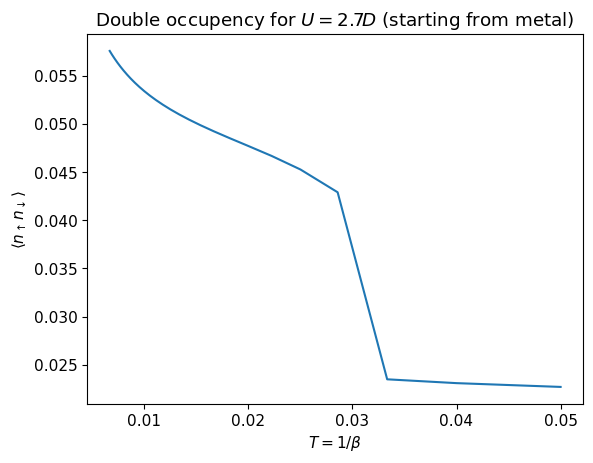

In [16]:
plt.figure()
plt.title(r"Double occupency for $U=2.7D$ (starting from metal)")
plt.plot(1/np.array(betas_ipt),docc)
plt.xlabel(r"$T=1/\beta$")
plt.ylabel(r"$\langle n_\uparrow n_\downarrow \rangle$")
plt.show()

When starting from the metal and increasing the temperature, the double occupency jumps down to a much lower value, indicating the transition to a Mott insulator. For a Mott insulator at half filling, each site can either have a spin up or down (little to no double occupency). This is two possible states, making the entropy of a site $\ln 2$, and since the entropy is extensive, the entropy of the whole Mott insulator is $L \ln 2$. On the other hand, the entropy for the metal is lower, making the insulator more stable.

# 3. Real-space DMFT with IPT for inhomogeneous one-dimensional chains

## 3.1 The model (Ch. 7 of the notes)

We come back to the inhomogeneous Hubbard chain of the DFT lectures:
$$
H=-t\sum_{i=1}^{L-1}\sum_\sigma\left(c^\dagger_{i\sigma}c_{i+1,\sigma}+{\rm h.c.}\right)+U\sum_{i=1}^Ln_{i\uparrow}n_{i\downarrow}+\sum_{i=1}^L v_i\,n_i ,
$$
with open boundary conditions, $N$ electrons and an external potential $v_i$. From now on $t=1$ is the energy unit.

## 3.2 Real-space DMFT equations

We keep the DMFT approximation — a **local** self-energy — but allow it to depend on the site, $\Sigma_{ij}(i\omega_n)=\delta_{ij}\Sigma_i(i\omega_n)$ (Sec. 7.2 of the notes). The lattice Green's function is then an $L\times L$ matrix at each Matsubara frequency:
$$
\mathbf G(i\omega_n)=\left[(i\omega_n+\mu)\mathbb 1-\mathbf h-\boldsymbol\Sigma(i\omega_n)\right]^{-1},
$$
where $\mathbf h$ is the $L\times L$ one-body matrix (hopping and potential). This matrix inversion replaces the Bethe-lattice relation $\Delta=t^2G$ of §1. Each site $i$ is an impurity with its own Weiss field (eq. 7.5 of the notes):
$$
\mathcal G_{0,i}^{-1}(i\omega_n)=G_{ii}(i\omega_n)^{-1}+\Sigma_i(i\omega_n).
$$

## 3.3 IPT away from half filling

In a trap the density changes from site to site, and most sites are **not** half filled: we cannot use the half-filling formula $\Sigma=U^2\mathcal G_0^3$ directly. We use its natural generalisation, second-order perturbation theory around the Hartree solution.

1. **Hartree term.** The static part of the self-energy is $U n_i/2$ (with $n_i$ the total density of site $i$, so that $n_i/2$ is the density per spin). We include it in a shifted Weiss field,
$$
\tilde{\mathcal G}_{i}^{-1}(i\omega_n)=\mathcal G_{0,i}^{-1}(i\omega_n)-\frac{U n_i}{2}.
$$
2. **Second-order term.** The second-order diagram, computed with $\tilde{\mathcal G}_i$, is
$$
\Sigma^{(2)}_i(\tau)=-U^2\,\tilde{\mathcal G}_i(\tau)^2\,\tilde{\mathcal G}_i(-\tau)=U^2\,\tilde{\mathcal G}_i(\tau)^2\,\tilde{\mathcal G}_i(\beta-\tau),
$$
where we used the antiperiodicity $G(-\tau)=-G(\beta-\tau)$ (Sec. 2.3.2 of the notes).
3. The self-energy of site $i$ is $\Sigma_i(i\omega_n)=\dfrac{Un_i}{2}+\Sigma^{(2)}_i(i\omega_n)$.

At half filling, particle–hole symmetry gives $\tilde{\mathcal G}(\beta-\tau)=\tilde{\mathcal G}(\tau)$, and we recover $\Sigma=U^2\mathcal G_0^3$ of §1, with the Hartree term $U/2$ absorbed in $\mu$.

**Hartree–Fock for free.** If we drop $\Sigma^{(2)}$, only the static Hartree term is left: this is the restricted (paramagnetic) Hartree–Fock approximation, i.e. static mean field. The same code thus gives both a static and a dynamical mean-field theory, which we will compare.

**A word of caution.** Away from half filling this IPT is exact at weak coupling, but it no longer reproduces the atomic limit. It is reliable for $U$ smaller than or comparable to the bandwidth ($4t$ for the chain). Better schemes exist, e.g. the modified IPT of H. Kajueter and G. Kotliar, Phys. Rev. Lett. 77, 131 (1996), at the price of a more complicated formula.

## 3.4 Densities

The lattice density is a Matsubara sum, which converges slowly. As in §0, we subtract the Green's function of a reference quadratic Hamiltonian, $\mathbf h+\boldsymbol\Sigma_\infty$, whose density is known exactly ($\Sigma_{\infty,i}=Un_i/2$ is the Hartree term), and sum only the remainder (Appendix C.3 of the notes):
$$
n_i=2\left\{n^{\rm ref}_i+\frac{2}{\beta}\sum_{n\ge0}\mathrm{Re}\left[G_{ii}(i\omega_n)-G^{\rm ref}_{ii}(i\omega_n)\right]\right\}.
$$
The chemical potential is fixed at each iteration by requiring $\sum_i n_i=N$ (root finding with `brentq`).

**Double occupancy.** Generalising the formula of §1.3, with $\Sigma^{(2)}_i=\Sigma_i-Un_i/2$,
$$
\langle n_{i\uparrow}n_{i\downarrow}\rangle=\frac{n_i^2}{4}+\frac{2}{\beta U}\sum_{n\ge0}\mathrm{Re}\left[\Sigma^{(2)}_i(i\omega_n)\,G_{ii}(i\omega_n)\right].
$$
The first term is the uncorrelated (Hartree–Fock) value; the second one is the correction due to dynamical correlations.

In [17]:
def chain_one_body_matrix(L, t=1.0, potential=None):
    '''L x L one-body matrix of an open chain with hopping t and site potential v_i.'''
    h = np.zeros((L, L))
    for i in range(L - 1):
        h[i, i + 1] = h[i + 1, i] = -t
    if potential is not None:
        h += np.diag(potential)
    return h


def fermi(e, beta):
    '''Fermi-Dirac distribution, written with tanh to avoid overflows.'''
    return 0.5 * (1.0 - np.tanh(0.5 * beta * e))


def lattice_green_function(h, Sigma, mu, iw):
    '''G_ij(i w_n) = [(i w_n + mu) 1 - h - diag(Sigma(i w_n))]^{-1}, array of shape (n_w, L, L).'''
    L = h.shape[0]
    return np.array([np.linalg.inv((z + mu) * np.eye(L) - h - np.diag(s)) for z, s in zip(iw, Sigma)])


def lattice_density(h, Sigma, Sigma_inf, mu, iw, beta):
    '''Site densities (both spins) and lattice Green's function, with the reference subtraction.'''
    e, W = np.linalg.eigh(h + np.diag(Sigma_inf))            # reference quadratic Hamiltonian
    n_ref = (np.abs(W)**2) @ fermi(e - mu, beta)
    G = lattice_green_function(h, Sigma, mu, iw)
    G_ref_diag = np.einsum("ik,nk->ni", np.abs(W)**2, 1.0 / (iw[:, None] + mu - e[None, :]))
    correction = (np.einsum("nii->ni", G) - G_ref_diag).real.sum(0)
    return 2.0 * (n_ref + 2.0 / beta * correction), G


def ipt_second_order(G_tilde_iw, U, grid):
    '''Second-order self-energy away from half filling: Sigma2(tau) = U^2 G(tau)^2 G(beta - tau).

    On our uniform tau grid, G(beta - tau) is simply the array G(tau) read backwards.
    '''
    G_tau = grid.to_tau(G_tilde_iw)
    return grid.to_iw(U**2 * G_tau**2 * G_tau[::-1])

**Check of `ipt_second_order`.** At half filling it must give back the IPT self-energy of §1. We use the converged Bethe-lattice Weiss field at $U=2D$.

In [18]:
res = dmft_ipt(2.0, grid)
Sigma_general = ipt_second_order(res["G0"], 2.0, grid)
Sigma_half_filling = ipt_self_energy(res["G0"], 2.0, grid)
print(f"max |Sigma_general - Sigma_half_filling| = {np.abs(Sigma_general - Sigma_half_filling).max():.1e}")

max |Sigma_general - Sigma_half_filling| = 2.4e-16


## 3.5 The real-space DMFT loop

**Task.** Write `real_space_dmft(h, U, N, beta, ...)` implementing the loop:
1. find $\mu$ such that $\sum_i n_i=N$, and compute $\mathbf G(i\omega_n)$ and the densities $n_i$;
2. for each site: Weiss field $\mathcal G_{0,i}^{-1}=G_{ii}^{-1}+\Sigma_i$, shifted Weiss field $\tilde{\mathcal G}_i$, and new self-energy $\Sigma_i=Un_i/2+\Sigma^{(2)}_i$;
3. mix the new and old self-energies, and iterate until both $\Sigma$ and the densities stop changing.

Add a flag `dynamical=True`: with `dynamical=False`, $\Sigma^{(2)}$ is set to zero and the code performs Hartree–Fock. Start from the Hartree self-energy of a uniform density, $\Sigma_i=UN/(2L)$. Strong interactions need strong damping: use `mixing=0.2`.

In [19]:
# TODO: complete the real-space DMFT loop
def real_space_dmft(h, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False):
    '''Paramagnetic real-space DMFT for a chain with one-body matrix h, Hartree-corrected IPT solver.

    With dynamical=False only the Hartree term is kept: restricted Hartree-Fock.
    '''
    L = h.shape[0]
    grid = MatsubaraGrid(beta, n_frequencies(beta))
    iw = grid.iw

    n = np.full(L, N / L)                                      # start: uniform density
    Sigma = np.tile(U * n / 2, (len(iw), 1)).astype(complex)   # Hartree self-energy

    for iteration in range(1, max_iter + 1):
        # 1) chemical potential (brentq on sum_i n_i - N), lattice Green's function and densities
        mu = brentq(lambda m: lattice_density(h, Sigma, U * n / 2, m, iw, beta)[0].sum() - N,
                    -20.0, 20.0, xtol=1e-10)
        n_new, G =  lattice_density(h, Sigma, U*n/2, mu, iw, beta)

        # 2) one impurity problem per site, solved with IPT
        Sigma_new = np.empty_like(Sigma)
        for i in range(L):
            G0_inv = (1/G[:,i,i]+Sigma[:,i])                                   # Weiss field of site i
            Sigma_new[:, i] = U*n[i]/2                        # Hartree term U n_i / 2
            if dynamical:
                G_tilde_iw = 1/(G0_inv - U*n[i]/2)                              # Hartree-shifted Weiss field
                Sigma_new[:, i] += ipt_second_order(G_tilde_iw, U, grid)                     # second-order term (ipt_second_order)

        # 3) convergence check on Sigma and n, and mixing
        error = max(np.abs(n-n_new))
        error_sigma = max([max(np.abs(Sigma[i]-Sigma_new[i])) for i in range(L)])
        Sigma = mixing*Sigma_new + (1-mixing)*Sigma
        n = n_new
        if error < tol:
            break

    # double occupancy: uncorrelated part n^2/4 plus the dynamical correction
    G_diag = np.einsum("nii->ni", G)
    Sigma2 = Sigma - U * n / 2
    docc = n**2 / 4
    if U > 0:
        docc = docc + 2.0 / (beta * U) * (Sigma2 * G_diag).real.sum(0)
    return {"n": n, "docc": docc, "mu": mu, "Sigma": Sigma, "G_diag": G_diag, "grid": grid,
            "iterations": iteration, "error": error}

**First check.** At $U=0$ real-space DMFT must give the exact non-interacting density of the chain, which we compute directly from the eigenstates of $\mathbf h$:
$n_i=2\sum_k|W_{ik}|^2 f(\varepsilon_k-\mu)$.

In [20]:
L, N = 12, 10
sites = np.arange(1, L + 1)
trap = 0.1 * (sites - (L + 1) / 2)**2
h_trap = chain_one_body_matrix(L, t=1.0, potential=trap)

res0 = real_space_dmft(h_trap, 0.0, N)
e, W = np.linalg.eigh(h_trap)
n_exact_U0 = 2 * (np.abs(W)**2) @ fermi(e - res0["mu"], 50.0)
print(f"U = 0: {res0['iterations']} iteration(s), max |n_DMFT - n_exact| = {np.abs(res0['n'] - n_exact_U0).max():.1e}")

U = 0: 2 iteration(s), max |n_DMFT - n_exact| = 6.7e-16


# 4. Trapped fermions in one dimension

We consider $N=10$ fermions ($N_\uparrow=N_\downarrow=5$) on $L=12$ sites in a harmonic trap, as in Ch. 7 of the notes:
$$
v_i=V_2\left(i-\frac{L+1}{2}\right)^2,\qquad V_2=0.1\,t .
$$
This geometry mimics cold fermionic atoms in an optical lattice with a harmonic confinement. In such experiments the Mott insulator is detected as a plateau of the density at one atom per site in the centre of the trap.

**Exact reference.** The cell below contains the exact ground-state densities $n_i$ and double occupancies $\langle n_{i\uparrow}n_{i\downarrow}\rangle$ for this system. They were obtained by exact diagonalisation of the Hubbard chain (Hilbert space of $\binom{12}{5}^2=627\,264$ states), with the matrix-free Hubbard operator of TP1 adapted to the open chain with the trap. You may recompute them with your TP1 code.

In [21]:
# Exact ground state of the trapped chain: L = 12, N_up = N_dn = 5, V2 = 0.1 t (sites 1..12)
exact = {
    0.0: {"n":    [0.0624, 0.4533, 1.0004, 0.9706, 1.2822, 1.2311, 1.2311, 1.2822, 0.9706, 1.0004, 0.4533, 0.0624],
          "docc": [0.0010, 0.0514, 0.2502, 0.2355, 0.4110, 0.3789, 0.3789, 0.4110, 0.2355, 0.2502, 0.0514, 0.0010]},
    2.0: {"n":    [0.1774, 0.7174, 0.9223, 0.9723, 1.1036, 1.1070, 1.1070, 1.1036, 0.9723, 0.9223, 0.7174, 0.1774],
          "docc": [0.0023, 0.0666, 0.1456, 0.1664, 0.2365, 0.2380, 0.2380, 0.2365, 0.1664, 0.1456, 0.0666, 0.0023]},
    4.0: {"n":    [0.2799, 0.7870, 0.9173, 0.9784, 1.0180, 1.0195, 1.0195, 1.0180, 0.9784, 0.9173, 0.7870, 0.2799],
          "docc": [0.0024, 0.0517, 0.0790, 0.0948, 0.1135, 0.1124, 0.1124, 0.1135, 0.0948, 0.0790, 0.0517, 0.0024]},
    6.0: {"n":    [0.3250, 0.7673, 0.9183, 0.9827, 1.0024, 1.0042, 1.0042, 1.0024, 0.9827, 0.9183, 0.7673, 0.3250],
          "docc": [0.0018, 0.0330, 0.0457, 0.0551, 0.0618, 0.0610, 0.0610, 0.0618, 0.0551, 0.0457, 0.0330, 0.0018]},
    8.0: {"n":    [0.3483, 0.7468, 0.9194, 0.9847, 0.9994, 1.0013, 1.0013, 0.9994, 0.9847, 0.9194, 0.7468, 0.3483],
          "docc": [0.0013, 0.0218, 0.0289, 0.0348, 0.0381, 0.0377, 0.0377, 0.0381, 0.0348, 0.0289, 0.0218, 0.0013]},
}

**Task.**
1. For $U/t=0,2,4$, compute the density and double-occupancy profiles with Hartree–Fock (`dynamical=False`) and with real-space DMFT (`dynamical=True`).
2. Plot them together with the exact results, and print the values at the centre of the trap.

*Running time: about 20 s.*

In [30]:
# Helper functions (given)
def plot_profiles(profiles, have_exact=True):
    Us = list(profiles)
    fig, ax = plt.subplots(2, len(Us), figsize=(4.6 * len(Us), 6.5), sharex=True)
    for k, U in enumerate(Us):
        for name, mk, col in [("HF", "s--", "C3"), ("DMFT", "^-", "C0")]:
            ax[0, k].plot(sites, profiles[U][name]["n"], mk, color=col, ms=5,
                          label="Hartree-Fock" if name == "HF" else "real-space DMFT (IPT)")
            ax[1, k].plot(sites, profiles[U][name]["docc"], mk, color=col, ms=5)
        if U in exact and have_exact:
            ax[0, k].plot(sites, exact[U]["n"], "ko-", ms=4, label="exact")
            ax[1, k].plot(sites, exact[U]["docc"], "ko-", ms=4)
        ax[0, k].plot(sites, trap / trap.max(), ":", color="gray", label="trap (rescaled)")
        ax[0, k].set(title=f"$U/t={U:g}$", ylim=(0, 1.45))
        ax[1, k].set(xlabel="site $i$", ylim=(0, 0.45))
    ax[0, 0].set_ylabel(r"$n_i$"); ax[1, 0].set_ylabel(r"$\langle n_{i\uparrow}n_{i\downarrow}\rangle$")
    ax[0, 0].legend(fontsize=9)
    plt.tight_layout(); plt.show()


def print_centre(profiles, i=5):
    print(f"centre of the trap (site {i + 1}):")
    print("  U/t   n exact   n HF   n DMFT   docc exact   docc HF   docc DMFT")
    for U in profiles:
        hf, dm = profiles[U]["HF"], profiles[U]["DMFT"]
        ex_n = exact[U]["n"][i] if U in exact else np.nan
        ex_d = exact[U]["docc"][i] if U in exact else np.nan
        print(f"  {U:3.0f}   {ex_n:7.3f}  {hf['n'][i]:6.3f}  {dm['n'][i]:6.3f}"
              f"   {ex_d:10.4f}  {hf['docc'][i]:8.4f}  {dm['docc'][i]:9.4f}")

U/t = 0.0: HF 2 iterations, DMFT 2 iterations (2.7 s)
U/t = 2.0: HF 32 iterations, DMFT 31 iterations (38.7 s)
U/t = 4.0: HF 24 iterations, DMFT 35 iterations (28.6 s)


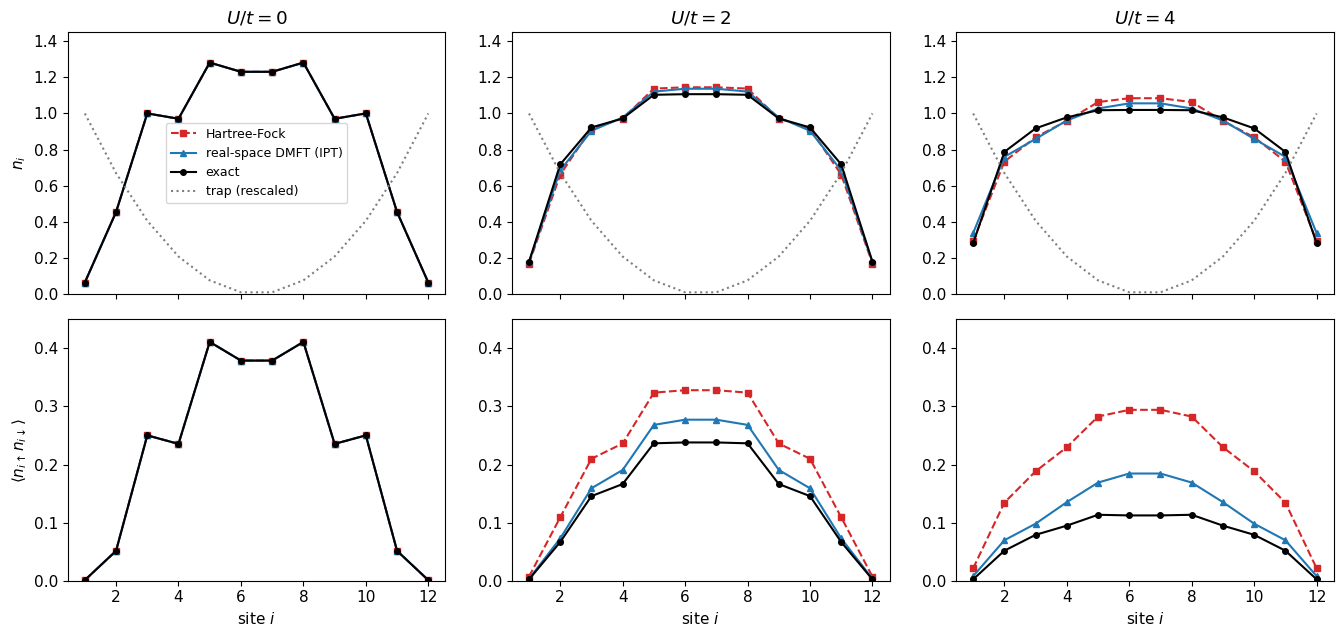

centre of the trap (site 6):
  U/t   n exact   n HF   n DMFT   docc exact   docc HF   docc DMFT
    0     1.231   1.231   1.231       0.3789    0.3789     0.3789
    2     1.107   1.145   1.137       0.2380    0.3279     0.2772
    4     1.020   1.085   1.056       0.1124    0.2941     0.1845


In [23]:
# TODO: for U = 0, 2, 4 run Hartree-Fock (dynamical=False) and DMFT (dynamical=True)
profiles = {}
N = 10
trap = 0.1 * (sites - (L + 1) / 2)**2
h_trap = chain_one_body_matrix(L, t=1.0, potential=trap)
for U in [0.0, 2.0, 4.0]:
    t0 = time.time()
    hf = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=False, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    dmft = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    profiles[U] = {"HF": hf, "DMFT": dmft}
    print(f"U/t = {U}: HF {hf['iterations']} iterations, DMFT {dmft['iterations']} iterations"
          f" ({time.time() - t0:.1f} s)")

plot_profiles(profiles)
print_centre(profiles)

**Discussion** (compare with Sec. 7.4 of the notes).
* At $U=0$ both methods are exact: the Friedel-like oscillations of the density are a single-particle, finite-size effect.
* **Double occupancy.** Hartree–Fock gives the uncorrelated value $n_i^2/4$: a static mean field does not suppress double occupancy beyond the change of density. Real-space DMFT reduces it substantially, towards the exact values: this is the local, dynamical correlation that DMFT is designed to capture.
* **Density.** Correlations push electrons away from the centre of the trap and flatten the profile towards $n_i\simeq1$. DMFT moves the density in the right direction compared with Hartree–Fock, but with IPT the improvement is only partial.

## 4.1 Strong coupling: the limits of IPT

**Task.** Repeat the calculation for $U/t=6$ and $8$. Compare the double occupancy at the centre of the trap with the exact one.

*Running time: about 30 s.*

U/t = 6.0: HF 25 iterations, DMFT 104 iterations (55.9 s)
U/t = 8.0: HF 38 iterations, DMFT 64 iterations (44.2 s)


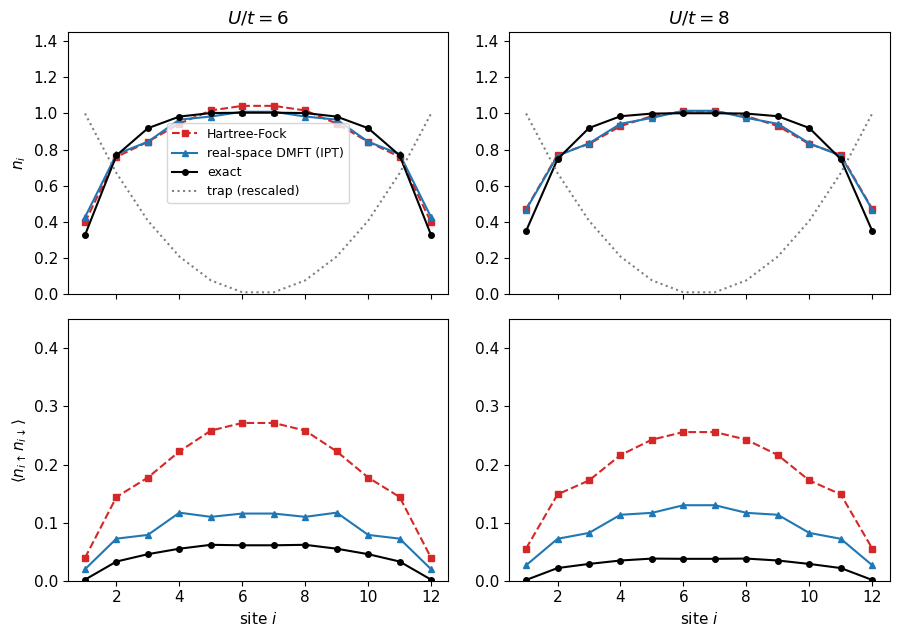

centre of the trap (site 6):
  U/t   n exact   n HF   n DMFT   docc exact   docc HF   docc DMFT
    6     1.004   1.042   1.009       0.0610    0.2716     0.1156
    8     1.001   1.012   1.015       0.0377    0.2558     0.1300


In [24]:
# TODO: same as above for U = 6 and 8, stored in profiles_strong, then plot and print
profiles_strong = {}
for U in [6.0, 8.0]:
    t0 = time.time()
    hf = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=False, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    dmft = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    profiles_strong[U] = {"HF": hf, "DMFT": dmft}
    print(f"U/t = {U}: HF {hf['iterations']} iterations, DMFT {dmft['iterations']} iterations"
          f" ({time.time() - t0:.1f} s)")

plot_profiles(profiles_strong)
print_centre(profiles_strong)

At strong coupling the exact solution develops an incompressible **Mott plateau**, $n_i\simeq1$ in the centre of the trap, with a strongly suppressed double occupancy. Real-space DMFT with IPT still improves on Hartree–Fock, but it overestimates the double occupancy by a large factor. Two reasons:

* **The solver.** Away from half filling, second-order perturbation theory does not reproduce the atomic limit, so it cannot describe the strongly suppressed double occupancy of a nearly localised electron. This is a limitation of IPT, not of DMFT: with an exact impurity solver (for example exact diagonalisation, Ch. 7 of the notes), the double occupancy at $U=8t$ is close to the exact one.
* **The approximation.** In one dimension the Mott gap opens for any $U>0$ because of short-range antiferromagnetic correlations, which single-site DMFT does not contain, whatever the solver.

## 4.2 Questions and extensions

1. Plot $\mathrm{Im}\,\Sigma_i(i\omega_n)$ for a site at the centre and a site at the edge of the trap, e.g. from `profiles[4.0]["DMFT"]["Sigma"]`. Where are correlations strongest? Relate the slope at small $\omega_n$ to a local quasiparticle weight $Z_i$.
2. **Other geometries.** Replace the harmonic trap with: (a) a flat box with hard walls (no potential); (b) a single impurity potential, $v_i=V_0\,\delta_{i,i_0}$; (c) a double well, $v_i=V_4(x_i^2-a^2)^2$ with $x_i=i-(L+1)/2$. Compare Hartree–Fock and DMFT. (There are no exact data for these cases: you can compute them with your TP1 code.)
3. Make the chain longer ($L=30$, $N=24$) — something exact diagonalisation cannot do. How does the computing time of real-space DMFT scale with $L$?

U/t = 4.0: HF 24 iterations, DMFT 35 iterations (32.2 s)


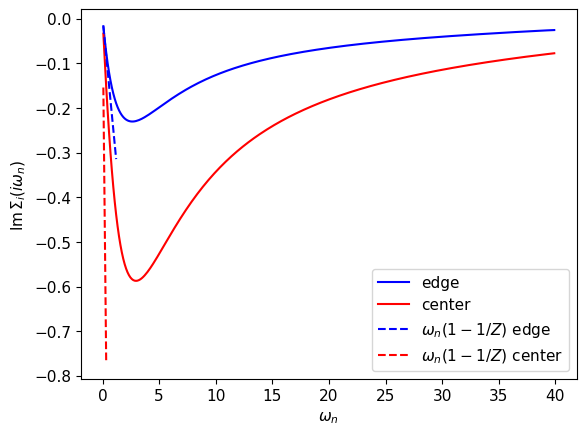

Fitted Z_0=0.8019756410110577, Computed Z_0=0.7916042300905249
Fitted Z_6=0.7361222271269207, Computed Z_6=0.289917936374553


In [50]:
### plot Im (Sigma[omega n , i ]) for a site at the centre and a site at the edge ###

N = 10
L = 12
sites = np.arange(1, L + 1)
trap = 0.1 * (sites - (L + 1) / 2)**2
h_trap = chain_one_body_matrix(L, t=1.0, potential=trap)
profiles = {}
for U in [4.0]:
    t0 = time.time()
    hf = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=False, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    dmft = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    profiles[U] = {"HF": hf, "DMFT": dmft}
    print(f"U/t = {U}: HF {hf['iterations']} iterations, DMFT {dmft['iterations']} iterations"
          f" ({time.time() - t0:.1f} s)")

sigmas = profiles[4.0]["DMFT"]["Sigma"] #(..., L)
beta = 50.0
grid = MatsubaraGrid(beta, n_frequencies(beta))

Z0 = quasiparticle_weight({"grid":grid, "Sigma":sigmas[0]})
Z6 = quasiparticle_weight({"grid":grid, "Sigma":sigmas[6]})

a0,b0 = np.polyfit(grid.iw.imag[:2],sigmas[:2,0].imag, 1)
a6,b6 = np.polyfit(grid.iw.imag[:10],sigmas[:10,6].imag,1)

plt.figure()
plt.plot(grid.iw.imag,sigmas[:,0].imag,"b-",label="edge")
plt.plot(grid.iw.imag,sigmas[:,6].imag,"r-",label="center")
plt.plot(grid.iw.imag[:10],grid.iw.imag[:10]*(1-1/Z0),"b--",label=r"$\omega_n (1-1/Z)$ edge")
plt.plot(grid.iw.imag[:3],grid.iw.imag[:3]*(1-1/Z6),"r--",label=r"$\omega_n (1-1/Z)$ center")
plt.xlabel(r"$\omega_n$")
plt.ylabel(r"$\mathrm{Im}\,\Sigma_i(i\omega_n)$")
plt.legend()
plt.show()

print(rf"Fitted Z_0={1/(1-a0)}, Computed Z_0={Z0}")
print(rf"Fitted Z_6={1/(1-a6)}, Computed Z_6={Z6}")

The correlations are the strongest at the center of the trap, where the density is higher. We can see that the local quasiparticle weight can be related to the slope at small $\omega$, through $\mathrm{Im}\,\Sigma_i(i\omega_n) = (1-1/Z_i)\omega_n$.

U/t = 0.0: HF 2 iterations, DMFT 2 iterations (2.0 s)
U/t = 2.0: HF 19 iterations, DMFT 34 iterations (26.1 s)
U/t = 4.0: HF 17 iterations, DMFT 38 iterations (24.2 s)


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_3444\1711788574.py:13: RuntimeWarning: invalid value encountered in divide
  ax[0, k].plot(sites, trap / trap.max(), ":", color="gray", label="trap (rescaled)")


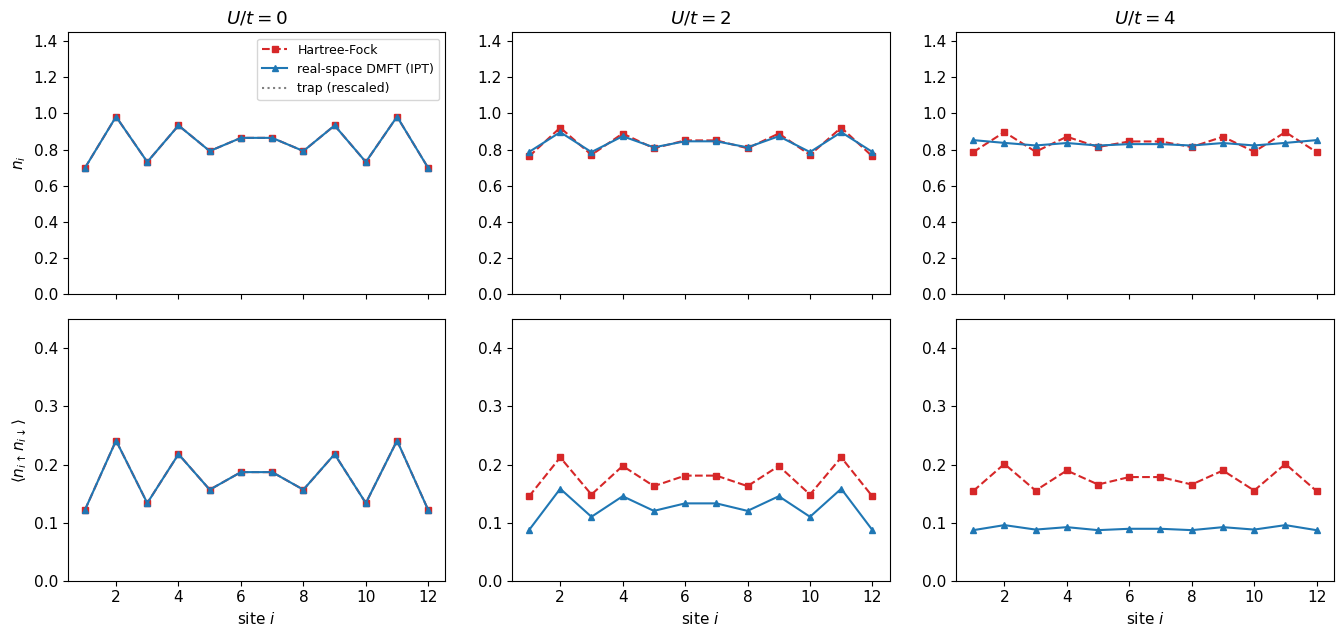

centre of the trap (site 6):
  U/t   n exact   n HF   n DMFT   docc exact   docc HF   docc DMFT
    0     1.231   0.865   0.865       0.3789    0.1869     0.1869
    2     1.107   0.851   0.846       0.2380    0.1809     0.1331
    4     1.020   0.845   0.830       0.1124    0.1784     0.0894


In [31]:
### try other geometries ###

# no potential / flat box
profiles = {}
N = 10
trap = 0 * (sites - (L + 1) / 2)**2
h_trap = chain_one_body_matrix(L, t=1.0, potential=trap)
for U in [0.0, 2.0, 4.0]:
    t0 = time.time()
    hf = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=False, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    dmft = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    profiles[U] = {"HF": hf, "DMFT": dmft}
    print(f"U/t = {U}: HF {hf['iterations']} iterations, DMFT {dmft['iterations']} iterations"
          f" ({time.time() - t0:.1f} s)")

plot_profiles(profiles, have_exact=False)
print_centre(profiles)

U/t = 0.0: HF 2 iterations, DMFT 2 iterations (2.4 s)
U/t = 2.0: HF 26 iterations, DMFT 32 iterations (27.6 s)
U/t = 4.0: HF 22 iterations, DMFT 42 iterations (27.3 s)


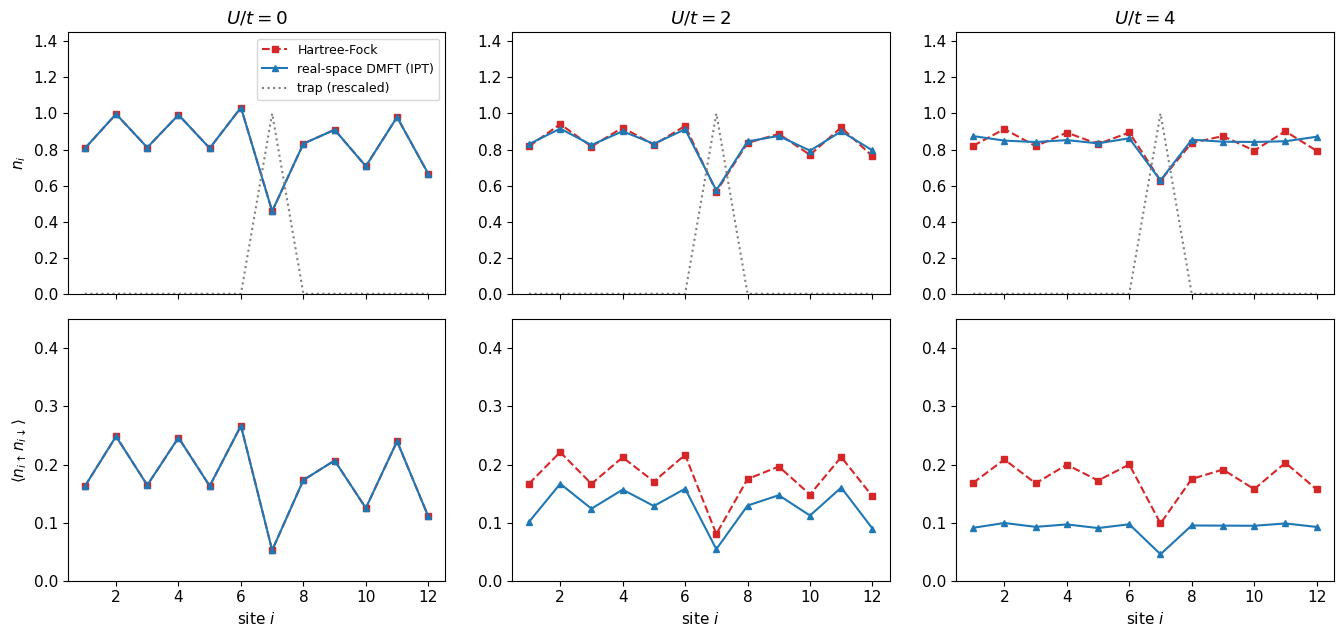

centre of the trap (site 6):
  U/t   n exact   n HF   n DMFT   docc exact   docc HF   docc DMFT
    0     1.231   1.033   1.033       0.3789    0.2668     0.2668
    2     1.107   0.931   0.912       0.2380    0.2167     0.1583
    4     1.020   0.895   0.862       0.1124    0.2001     0.0972


In [32]:
# single impurity potential

profiles = {}
V0 = 1
i_0 = 6
N = 10
trap = np.zeros_like(sites)
trap[i_0] = V0
h_trap = chain_one_body_matrix(L, t=1.0, potential=trap)
for U in [0.0, 2.0, 4.0]:
    t0 = time.time()
    hf = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=False, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    dmft = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    profiles[U] = {"HF": hf, "DMFT": dmft}
    print(f"U/t = {U}: HF {hf['iterations']} iterations, DMFT {dmft['iterations']} iterations"
          f" ({time.time() - t0:.1f} s)")

plot_profiles(profiles, have_exact=False)
print_centre(profiles)

U/t = 0.0: HF 2 iterations, DMFT 2 iterations (1.8 s)
U/t = 2.0: HF 29 iterations, DMFT 32 iterations (27.6 s)
U/t = 4.0: HF 26 iterations, DMFT 44 iterations (33.8 s)


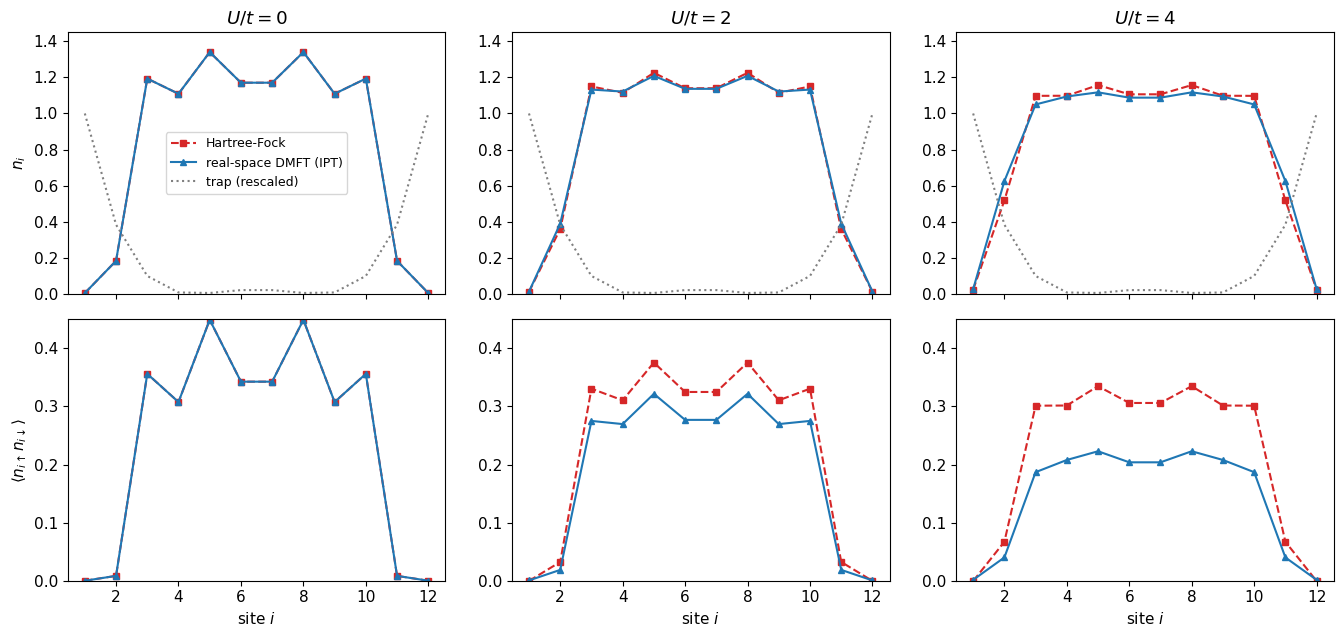

centre of the trap (site 6):
  U/t   n exact   n HF   n DMFT   docc exact   docc HF   docc DMFT
    0     1.231   1.171   1.171       0.3789    0.3426     0.3426
    2     1.107   1.140   1.137       0.2380    0.3249     0.2768
    4     1.020   1.106   1.088       0.1124    0.3059     0.2038


In [36]:
# double well

profiles = {}
N = 10
V4 = 0.01
a = 2
trap = V4 * ((sites - (L + 1) / 2)**2 -a**2)**2
h_trap = chain_one_body_matrix(L, t=1.0, potential=trap)
for U in [0.0, 2.0, 4.0]:
    t0 = time.time()
    hf = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=False, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    dmft = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    profiles[U] = {"HF": hf, "DMFT": dmft}
    print(f"U/t = {U}: HF {hf['iterations']} iterations, DMFT {dmft['iterations']} iterations"
          f" ({time.time() - t0:.1f} s)")

plot_profiles(profiles, have_exact=False)
print_centre(profiles)

In [38]:
### Longer chain ###

L = 30
N = 24 
sites = np.arange(1, L + 1)
profiles = {}

trap = 0.1 * (sites - (L + 1) / 2)**2
h_trap = chain_one_body_matrix(L, t=1.0, potential=trap)
for U in [0.0, 2.0, 4.0]:
    t0 = time.time()
    hf = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=False, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    dmft = real_space_dmft(h_trap, U, N, beta=50.0, dynamical=True, mixing=0.2, tol=1e-5, max_iter=600, verbose=False)
    profiles[U] = {"HF": hf, "DMFT": dmft}
    print(f"U/t = {U}: HF {hf['iterations']} iterations, DMFT {dmft['iterations']} iterations"
          f" ({time.time() - t0:.1f} s)")

plot_profiles(profiles)
print_centre(profiles)

U/t = 0.0: HF 2 iterations, DMFT 2 iterations (6.6 s)
U/t = 2.0: HF 33 iterations, DMFT 33 iterations (91.4 s)
U/t = 4.0: HF 32 iterations, DMFT 65 iterations (122.9 s)


ValueError: x and y must have same first dimension, but have shapes (30,) and (12,)